# 1 - Instalação, Descompactação do Adaptador LoRA e Carga do Modelo Ajustado

In [2]:
!pip install -q -U transformers peft accelerate bitsandbytes rouge-score scikit-learn pandas matplotlib seaborn tqdm

import os
import re
import json
import time
import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from rouge_score import rouge_scorer

# 1. Descompactar os adaptadores LoRA treinados
!unzip -q -o final_model.zip

# 2. Carregar dados de teste e intenções oficiais
with open("data/test_set_300.json", "r", encoding="utf-8") as f:
    test_data = json.load(f)

with open("data/valid_intents.json", "r", encoding="utf-8") as f:
    valid_intents = json.load(f)

INTENTS_STR = ", ".join(valid_intents)

# 3. Carregar modelo base + adaptador LoRA ajustado
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
ADAPTER_PATH = "lora_adapters/final_model"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

tokenizer = AutoTokenizer.from_pretrained(ADAPTER_PATH)
base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    torch_dtype=torch.float16,
    device_map="auto"
)
ft_model = PeftModel.from_pretrained(base_model, ADAPTER_PATH)
ft_model.eval()
print("Modelo Qwen2.5-1.5B + LoRA carregado com sucesso!")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Modelo Qwen2.5-1.5B + LoRA carregado com sucesso!


# 2 - Inferência nas 300 Mensagens do Gold Test Set

In [3]:
SYSTEM_PROMPT = f"""You are a customer support AI assistant.
Your task is to:
1. Classify the customer's message into EXACTLY ONE of the following 27 valid intents:
[{INTENTS_STR}]
2. Write a helpful, polite, and concise customer support response.

Respond ONLY with a valid JSON object using this exact format:
{{"intent": "<exact_intent_name>", "response": "<your_reply>"}}"""

def parse_model_output(raw_text: str):
    cleaned = re.sub(r"```json|```", "", raw_text).strip()
    try:
        data = json.loads(cleaned)
        intent = str(data.get("intent", "unknown")).strip().lower()
        response = str(data.get("response", "")).strip()
        return intent, response
    except Exception:
        found_intent = "unknown"
        for v_intent in valid_intents:
            if v_intent in cleaned.lower():
                found_intent = v_intent
                break
        return found_intent, cleaned

results_lora = []
for item in tqdm(test_data, desc="Qwen2.5-1.5B + LoRA (Test Set)"):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": item["instruction"]}
    ]
    text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer([text], return_tensors="pt").to(ft_model.device)

    t0 = time.perf_counter()
    with torch.no_grad():
        outputs = ft_model.generate(
            **inputs,
            max_new_tokens=180,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )
    latency = time.perf_counter() - t0

    generated_ids = outputs[0][inputs.input_ids.shape[1]:]
    raw_out = tokenizer.decode(generated_ids, skip_special_tokens=True)
    pred_intent, pred_resp = parse_model_output(raw_out)

    results_lora.append({
        "instruction": item["instruction"],
        "true_intent": item["intent"],
        "pred_intent": pred_intent,
        "true_response": item["response"],
        "pred_response": pred_resp,
        "latency_sec": latency
    })

os.makedirs("results", exist_ok=True)
df_qwen_lora = pd.DataFrame(results_lora)
df_qwen_lora.to_csv("results/preds_qwen_lora.csv", index=False)
print("Inferência concluída e salva em results/preds_qwen_lora.csv!")

Qwen2.5-1.5B + LoRA (Test Set):   0%|          | 0/300 [00:00<?, ?it/s]

Inferência concluída e salva em results/preds_qwen_lora.csv!


# 3 - Tabela Comparativa Final (4 Modelos lado a lado)


In [4]:
def evaluate_predictions(df_preds: pd.DataFrame, model_name: str, cost_per_1k_usd: float):
    y_true = df_preds["true_intent"].tolist()
    y_pred = df_preds["pred_intent"].tolist()

    acc = accuracy_score(y_true, y_pred)
    f1_macro = f1_score(y_true, y_pred, average="macro", zero_division=0)

    scorer = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)
    rouge_scores = [
        scorer.score(ref, pred)["rougeL"].fmeasure
        for ref, pred in zip(df_preds["true_response"], df_preds["pred_response"])
    ]
    avg_rouge = sum(rouge_scores) / len(rouge_scores)
    avg_latency = df_preds["latency_sec"].mean()

    return {
        "Modelo": model_name,
        "Acurácia (%)": round(acc * 100, 2),
        "F1-Macro (%)": round(f1_macro * 100, 2),
        "ROUGE-L": round(avg_rouge, 4),
        "Latência Média (s)": round(avg_latency, 3),
        "Custo / 1k msgs (USD)": round(cost_per_1k_usd, 4)
    }

df_qwen_zero = pd.read_csv("results/preds_qwen_zeroshot.csv")
df_qwen_few = pd.read_csv("results/preds_qwen_fewshot.csv")
df_gemini = pd.read_csv("results/preds_gemini_flash.csv")

cost_qwen_zero = (df_qwen_zero["latency_sec"].mean() / 3600) * 0.35 * 1000
cost_qwen_few = (df_qwen_few["latency_sec"].mean() / 3600) * 0.35 * 1000
cost_qwen_lora = (df_qwen_lora["latency_sec"].mean() / 3600) * 0.35 * 1000
cost_gemini_1k = 0.0004  # Valor obtido na medição real da API

final_summary = pd.DataFrame([
    evaluate_predictions(df_qwen_zero, "Qwen2.5-1.5B (Zero-Shot)", cost_qwen_zero),
    evaluate_predictions(df_qwen_few, "Qwen2.5-1.5B (Few-Shot)", cost_qwen_few),
    evaluate_predictions(df_qwen_lora, "Qwen2.5-1.5B + LoRA (Fine-Tuned)", cost_qwen_lora),
    evaluate_predictions(df_gemini, "Gemini 3.5 Flash-Lite (API)", cost_gemini_1k)
])

final_summary.to_csv("results/final_benchmark_summary.csv", index=False)
print("=== TABELA COMPARATIVA FINAL (GOLD TEST SET - 300 MENSAGENS) ===\n")
print(final_summary.to_string(index=False))

=== TABELA COMPARATIVA FINAL (GOLD TEST SET - 300 MENSAGENS) ===

                          Modelo  Acurácia (%)  F1-Macro (%)  ROUGE-L  Latência Média (s)  Custo / 1k msgs (USD)
        Qwen2.5-1.5B (Zero-Shot)         57.33         43.21   0.2025               1.980                 0.1925
         Qwen2.5-1.5B (Few-Shot)         53.67         36.20   0.1914               1.927                 0.1874
Qwen2.5-1.5B + LoRA (Fine-Tuned)         99.67         96.27   0.3716              13.620                 1.3242
     Gemini 3.5 Flash-Lite (API)         92.00         88.73   0.2162               0.973                 0.0004


Melhorar a latencia média do modelo treinado

# 4 - Geração dos Gráficos para o TCC e GitHub (results/*.png)

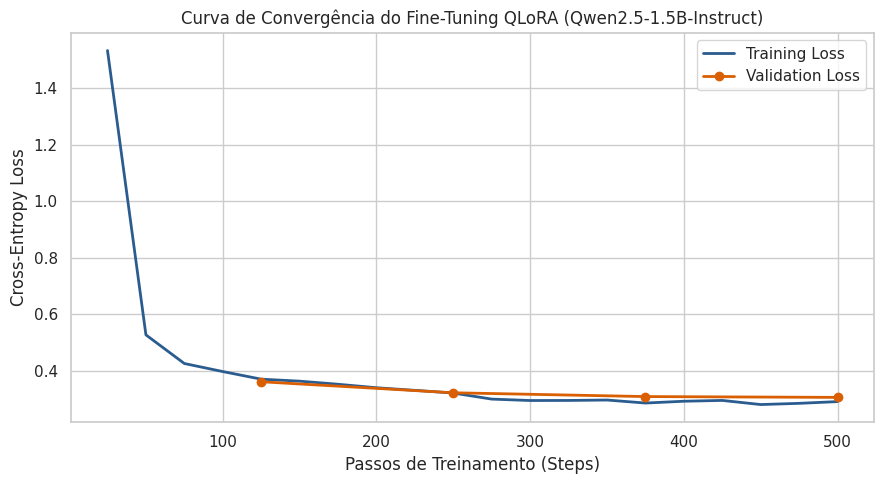

/tmp/ipykernel_14037/271723986.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=final_summary, x="Modelo", y="ROUGE-L", ax=axes[1], palette="Greens_d")


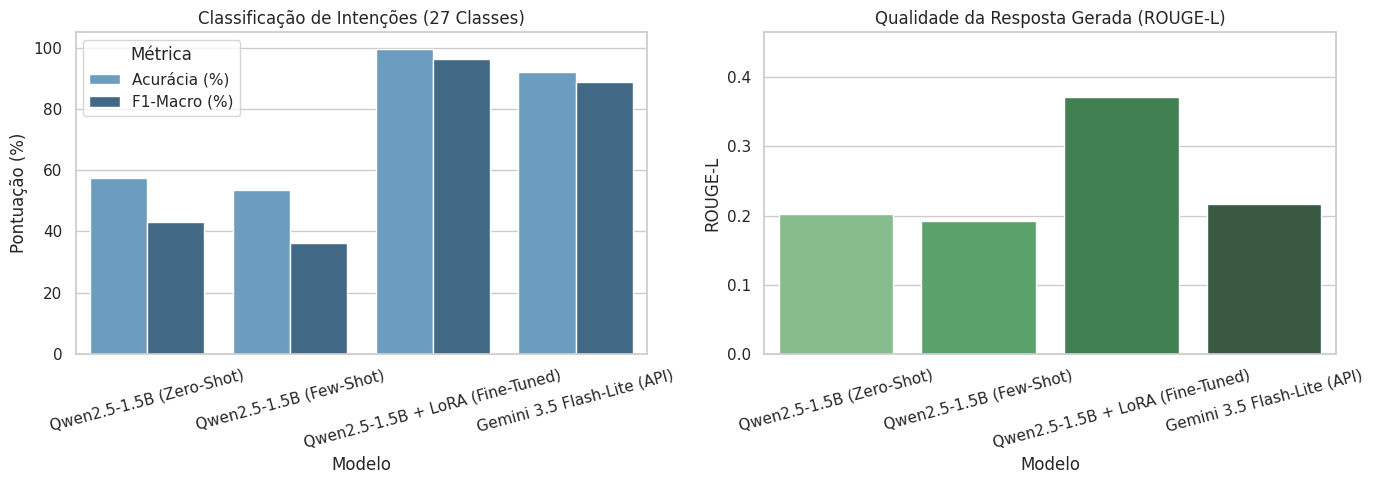

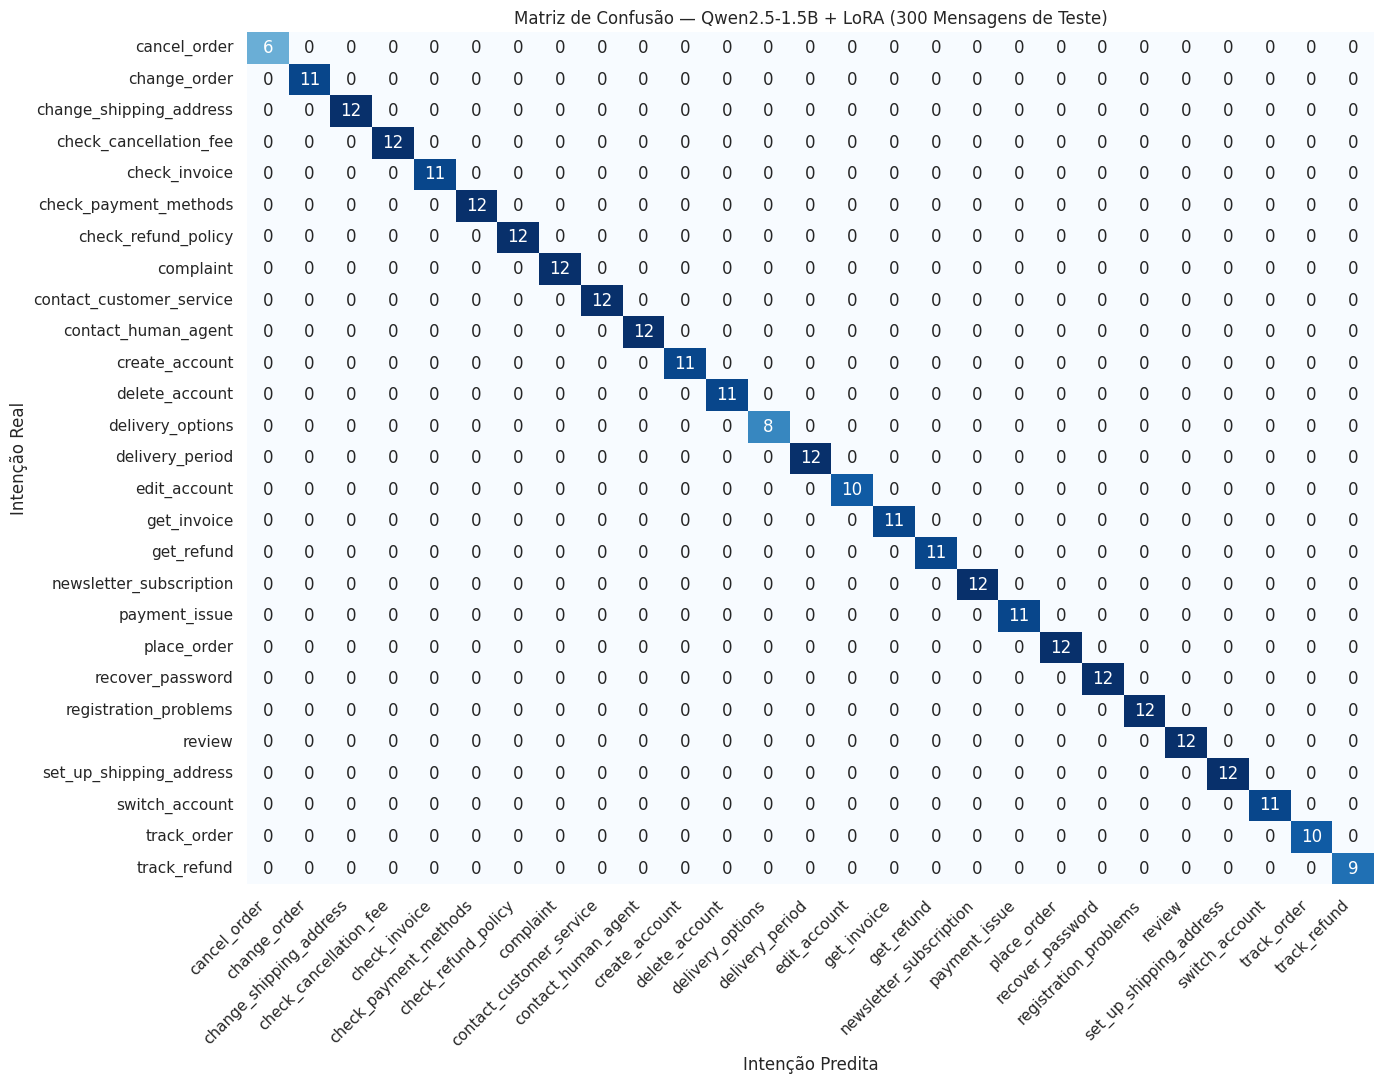

In [5]:
sns.set_theme(style="whitegrid")

# 1. Gráfico de Curva de Aprendizado (Training vs Validation Loss)
with open("results/training_history.json", "r") as f:
    history = json.load(f)

train_steps = [x["step"] for x in history if "loss" in x]
train_loss = [x["loss"] for x in history if "loss" in x]
eval_steps = [x["step"] for x in history if "eval_loss" in x]
eval_loss = [x["eval_loss"] for x in history if "eval_loss" in x]

plt.figure(figsize=(9, 5))
plt.plot(train_steps, train_loss, label="Training Loss", color="#2b5c8f", linewidth=2)
plt.plot(eval_steps, eval_loss, label="Validation Loss", color="#d95f02", marker="o", linewidth=2)
plt.title("Curva de Convergência do Fine-Tuning QLoRA (Qwen2.5-1.5B-Instruct)")
plt.xlabel("Passos de Treinamento (Steps)")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.tight_layout()
plt.savefig("results/lora_loss_curve.png", dpi=300)
plt.show()

# 2. Gráfico Comparativo de Desempenho (Acurácia, F1-Macro e ROUGE-L)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_melted = final_summary.melt(
    id_vars="Modelo",
    value_vars=["Acurácia (%)", "F1-Macro (%)"],
    var_name="Métrica",
    value_name="Pontuação (%)"
)
sns.barplot(data=df_melted, x="Modelo", y="Pontuação (%)", hue="Métrica", ax=axes[0], palette="Blues_d")
axes[0].set_title("Classificação de Intenções (27 Classes)")
axes[0].set_ylim(0, 105)
axes[0].tick_params(axis="x", rotation=15)

sns.barplot(data=final_summary, x="Modelo", y="ROUGE-L", ax=axes[1], palette="Greens_d")
axes[1].set_title("Qualidade da Resposta Gerada (ROUGE-L)")
axes[1].set_ylim(0, max(final_summary["ROUGE-L"]) * 1.25)
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig("results/models_comparison.png", dpi=300)
plt.show()

# 3. Matriz de Confusão do Modelo Ajustado (Qwen2.5-1.5B + LoRA)
cm = confusion_matrix(df_qwen_lora["true_intent"], df_qwen_lora["pred_intent"], labels=valid_intents)
plt.figure(figsize=(14, 11))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=valid_intents, yticklabels=valid_intents, cbar=False)
plt.title("Matriz de Confusão — Qwen2.5-1.5B + LoRA (300 Mensagens de Teste)")
plt.xlabel("Intenção Predita")
plt.ylabel("Intenção Real")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("results/confusion_matrix_lora.png", dpi=300)
plt.show()